<img src="MUML_header.svg" alt="Header" style="width:100%; height:auto;">

You have studied gradient descent (GD), stochastic gradient descent (SGD), and mini-batch gradient descent, as well as three simple learning rate decay policies: piecewise constant, exponential decay, and polynomial decay. In this lab, you will put these ideas into practice by implementing the training loop and the schedulers from scratch (without using `torch.optim` or `torch.optim.lr_scheduler`).

We will use as dataset a binary classification dataset (2D, non-linearly separable) generated with `sklearn.datasets.make_moons`. Starter code will load and transform the data into PyTorch tensors.



In [1]:
import numpy as np
import torch
import torch.nn as nn
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import time

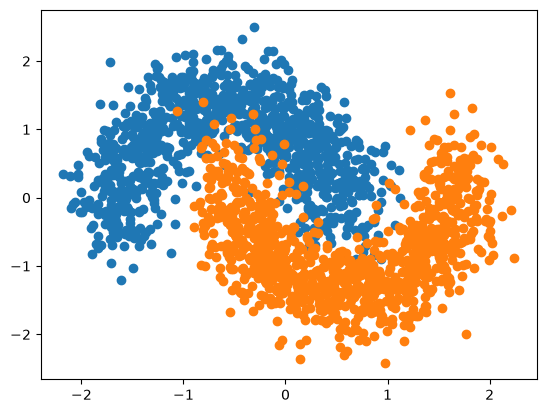

In [2]:
# Reproducibility
seed = 321
torch.manual_seed(seed)
np.random.seed(seed)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Data
X, y = make_moons(n_samples=2000, noise=0.2, random_state=seed)
scaler = StandardScaler()
X = scaler.fit_transform(X)
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=seed)

X_train = torch.tensor(X_train, dtype=torch.float32).to(DEVICE)
X_val = torch.tensor(X_val, dtype=torch.float32).to(DEVICE)

y_train = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1).to(DEVICE)
y_val = torch.tensor(y_val, dtype=torch.float32).unsqueeze(1).to(DEVICE)

plt.scatter(X[y==0,0],X[y==0,1])
plt.scatter(X[y==1,0],X[y==1,1])

The model for classification will be a simple 2-layer neural network (MLP):
* Input: 2
* Hidden layer: 64 units, ReLU activation
* Output: 1 unit, raw output (use `BCEWithLogitLoss`)

Implement the class, inheriting from `nn.Module`.

In [3]:
# Model
class SimpleMLP(nn.Module):

    def __init__(self, input_size=2, number_neurons=[64], output_size=1):
        super(SimpleMLP, self).__init__()
        layers = []
        in_dim = input_size
        for h_dim in number_neurons:
            layers.append(nn.Linear(in_dim, h_dim))
            layers.append(nn.ReLU())
            in_dim = h_dim
        layers.append(nn.Linear(in_dim, output_size))
        self.net = nn.Sequential(*layers)
        
    def forward(self, x):
        return self.net(x)


Implement manually your learning rate schedulers. Each one must be a function with the needed parameters (can be different for each function).

Decide whether your updates of the learning rate will be applied per iteration or per epoch. In practice:
* Per iteration is more common, as it gives a more granular control
* Per epoch is used with simpler schedulers or when fine precision is not so important

In [4]:
def piecewise_constant(step, lr_init, boundaries, values):
    lr = values[0]
    for i, b in enumerate(boundaries):
        if step >= b:
            lr = values[i + 1]
    return lr

def exponential_decay(step, lr_init, decay_rate=0.01):

    return lr_init * np.exp(-decay_rate * step)

def polynomial_decay(step, lr_init, beta, delta):
    return (lr_init) * ((beta*step+1)**(-delta))

Implement manually a function to provide the batches of the specified size. Use the instruction yield to create a generator.

In [5]:
def get_batches(X, y, batch_size, shuffle=True):
    N = len(X)
    if shuffle:
        indices = torch.randperm(N)
    else:
        indices = np.arrange(N) 
    for start in range(0, N, batch_size):
        end = start + batch_size
        idx = indices[start:end]
        yield X[idx], y[idx]

Create a function to calculate the accuracy of a model over a dataset.

In [6]:
def accuracy(model, X, y):
    model.eval()
    with torch.no_grad():
        logits = model(X)
        predictions = (logits >= 0).float()
        acc = (predictions == y).float().mean().item()
    return acc

Create a function for the manual training implementation:
* Shuffles the data at the beggining of each epoch (could be implemented in the function that provide batches)
* For each mini-batch compute the loss and update the parameters manually
* Log training loss per iteration and per epoch
* Log validation loss or accuracy per epoch

In [7]:
# Entrenamiento manual
from tqdm import tqdm

def train_manual(model, X_tr, y_tr, X_val, y_val,
                 batch_size=32, lr_init=1e-2, scheduler_fn=None,
                 num_epochs=50, scheduler_step_per='iteration'):
    """
    scheduler_step_per: 'iteration' or 'epoch'
    scheduler_fn: function(step)->lr
    """
    history = {
        'train_loss_iter': [],   
        'train_loss_epoch': [],  
        'val_loss_epoch': [],    
        'val_acc_epoch': [],     
        'lr_history': []         
    }
    criterion = nn.BCEWithLogitsLoss()    
    total_iterations = 0
    current_lr = lr_init

    pbar = tqdm(range(1, num_epochs + 1), desc="Training Model", unit="epoch")
    
    for epoch in pbar:
        model.train()
        epoch_loss = 0.0
        num_batches = 0

        if scheduler_step_per == 'epoch' and scheduler_fn is not None:
            current_lr = scheduler_fn(epoch - 1, lr_init) #revisar

        for x_batch, y_batch in get_batches(X_tr, y_tr, batch_size, shuffle=True):
            total_iterations += 1
            
            if scheduler_step_per == 'iteration' and scheduler_fn is not None:
                current_lr = scheduler_fn(total_iterations - 1, lr_init)#revisar

            history['lr_history'].append(current_lr)

            logits = model(x_batch)
            loss = criterion(logits, y_batch)

            loss.backward()

            with torch.no_grad():
                for param in model.parameters():
                    if param.grad is not None:
                        param -= current_lr * param.grad
                        param.grad.zero_()

            loss_val = loss.item()
            history['train_loss_iter'].append(loss_val)
            epoch_loss += loss_val
            num_batches += 1

        mean_train_loss = epoch_loss / num_batches
        history['train_loss_epoch'].append(mean_train_loss)

        model.eval()
        with torch.no_grad():
            val_logits = model(X_val)
            val_loss = criterion(val_logits, y_val).item()
            val_acc = accuracy(model, X_val, y_val)

        history['val_loss_epoch'].append(val_loss)
        history['val_acc_epoch'].append(val_acc)

        pbar.set_postfix({
            'Train Loss': f"{mean_train_loss:.4f}",
            'Val Loss': f"{val_loss:.4f}",
            'Val Acc': f"{val_acc:.4f}",
            'LR': f"{current_lr:.6f}"
        })

    return history

### Experiments
Test three batch sizes:
* batch_size=1 (SGD)
* batch_size=32 (mini-batch)
* batch_size=N (full_batch)

For each batch size, adjust the number of epochs and the learning rate schedule parameters so that training is observable and comparable.

For each experiment:
* Plot the training loss curve (error decreasing over epochs).
* Plot the validation accuracy curve (over epochs).

Present the results as paired plots (training loss + validation accuracy) for each batch size.

Write a short commentary for each experiment highlighting noteworthy observations (e.g., convergence speed, oscillations, stability, overfitting, or the effect of the learning rate schedule).

In [8]:
from functools import partial
N_samples = len(X_train)  # N = 1600

experiments_config = {
    "SGD (batch_size = 1)": {
        "batch_size": 1,
        "num_epochs": 20,
        "lr_init": 1e-3,  # Lower LR to prevent wild gradient oscillations
        "scheduler_step_per": "iteration",
        "scheduler_fn": partial(piecewise_constant, boundaries=[30, 70], values=[1e-3, 1e-4, 1e-5])
    },
    "Mini-batch GD (batch_size = 32)": {
        "batch_size": 32,
        "num_epochs": 100,
        "lr_init": 1e-2,  # Standard learning rate
        "scheduler_step_per": "epoch",
        "scheduler_fn": partial(exponential_decay, decay_rate=0.02)
    },
    "Full-batch GD (batch_size = N)": {
        "batch_size": N_samples,
        "num_epochs": 300,  # Requires significantly more epochs to converge
        "lr_init": 1e-1,  # Higher LR needed to speed up slow updates
        "scheduler_step_per": "epoch",
        "scheduler_fn": partial(polynomial_decay, beta=0.01, delta=0.5)
    }
}

histories = {}

for exp_name, config in experiments_config.items():
    print(f"\n--- Running Experiment: {exp_name} ---")
    
    # Re-initialize model with deterministic weights for fair comparison
    torch.manual_seed(seed)
    model = SimpleMLP(input_size=2, number_neurons=[64], output_size=1).to(DEVICE)
    
    hist = train_manual(
        model, X_train, y_train, X_val, y_val,
        batch_size=config["batch_size"],
        lr_init=config["lr_init"],
        scheduler_fn=config["scheduler_fn"],
        num_epochs=config["num_epochs"],
        scheduler_step_per=config["scheduler_step_per"]
    )
    histories[exp_name] = hist


--- Running Experiment: SGD (batch_size = 1) ---


Training Model: 100%|████████████████████████████████████████████████████████████████████| 20/20 [00:26<00:00,  1.34s/epoch, Train Loss=0.5167, Val Loss=0.5170, Val Acc=0.8775, LR=0.000010]



--- Running Experiment: Mini-batch GD (batch_size = 32) ---


Training Model: 100%|██████████████████████████████████████████████████████████████████| 100/100 [00:04<00:00, 22.40epoch/s, Train Loss=0.2648, Val Loss=0.2845, Val Acc=0.8800, LR=0.001381]



--- Running Experiment: Full-batch GD (batch_size = N) ---


Training Model: 100%|█████████████████████████████████████████████████████████████████| 300/300 [00:00<00:00, 400.04epoch/s, Train Loss=0.2669, Val Loss=0.2865, Val Acc=0.8775, LR=0.050063]


AttributeError: Text.set() got an unexpected keyword argument 'marker'

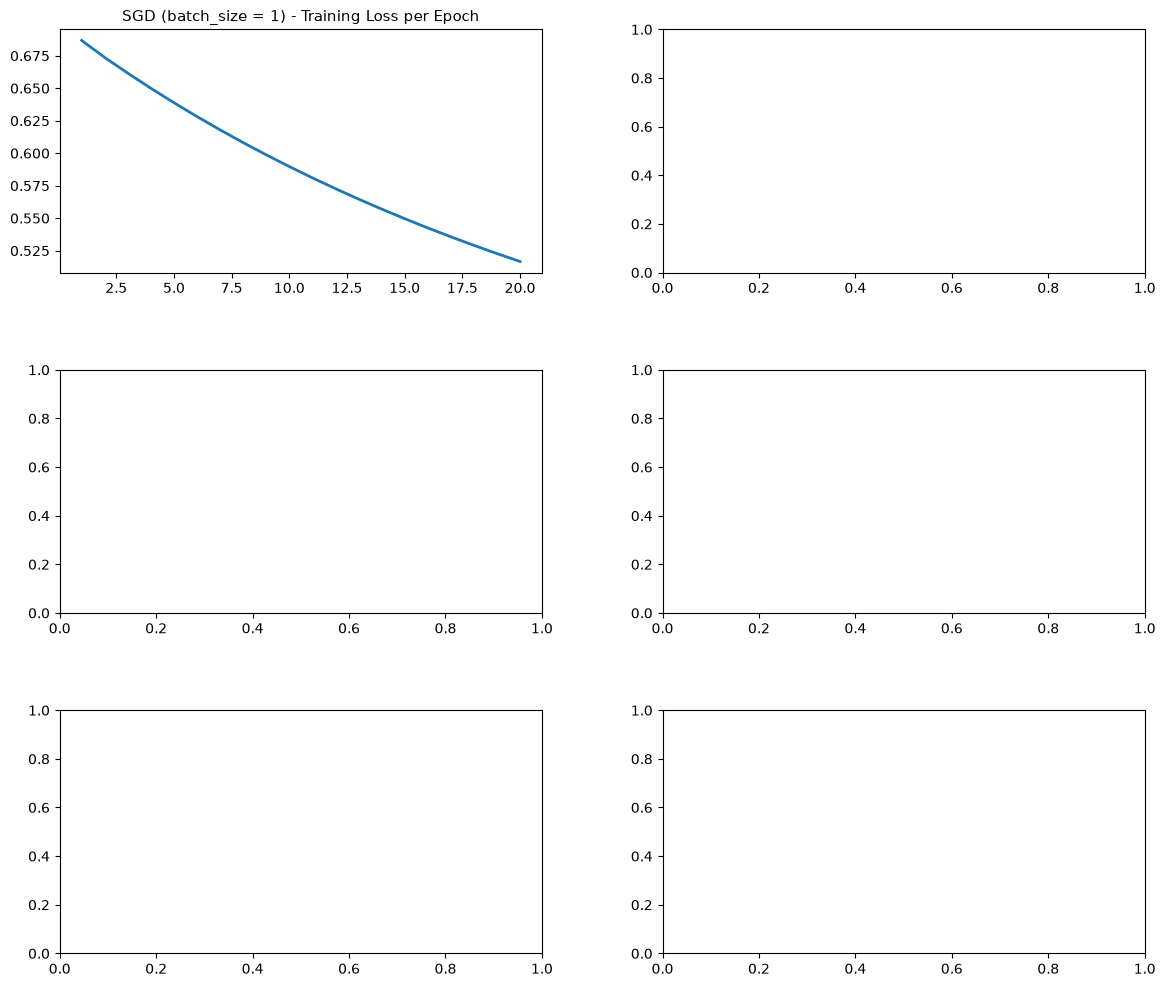

In [9]:
fig, axes = plt.subplots(3, 2, figsize=(14, 12))
plt.subplots_adjust(hspace=0.4, wspace=0.25)

for i, (exp_name, hist) in enumerate(histories.items()):
    epochs = range(1, len(hist['train_loss_epoch']) + 1)
    
    # Plot 1: Training Loss
    axes[i, 0].plot(epochs, hist['train_loss_epoch'], color='tab:blue', linewidth=2)
    axes[i, 0].set_title(f"{exp_name} - Training Loss per Epoch", fontsize=11, marker='o', fontweight='bold')
    axes[i, 0].set_xlabel("Epochs")
    axes[i, 0].set_ylabel("Loss")
    axes[i, 0].grid(True, linestyle='--', alpha=0.6)
    
    # Plot 2: Validation Accuracy
    axes[i, 1].plot(epochs, hist['val_acc_epoch'], color='tab:green', linewidth=2)
    axes[i, 1].set_title(f"{exp_name} - Validation Accuracy per Epoch", fontsize=11, marker='o', fontweight='bold')
    axes[i, 1].set_xlabel("Epochs")
    axes[i, 1].set_ylabel("Accuracy")
    axes[i, 1].set_ylim([0.45, 1.02])
    axes[i, 1].grid(True, linestyle='--', alpha=0.6)

plt.show()